In [18]:
!pip install PyMPDATA

In [19]:
import PyMPDATA
import numpy as np
import matplotlib.pyplot as plt

In [20]:
print(PyMPDATA.__file__)

/usr/local/lib/python3.13/dist-packages/PyMPDATA/__init__.py


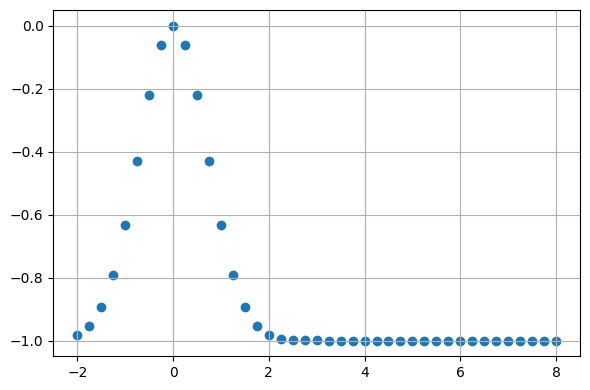

In [28]:
x = np.linspace(-2, 8, 41)
y = np.exp(-x ** 2) - 1

plt.figure(figsize=(6,4))
plt.scatter(x, y)
plt.grid(True)
plt.tight_layout()
plt.show()

In [32]:
from PyMPDATA import ScalarField, VectorField, Options, Stepper, Solver, boundary_conditions

common = {'halo': (options := Options(nonoscillatory=True)).n_halo ,
          'boundary_conditions': (boundary_conditions.Periodic(),)}

advector = VectorField(**common, data= (np.full(x.size + 1, 0.25), ))
advectee = ScalarField(**common, data= y)

stepper = Stepper(n_dims=1, options=options)
solver = Solver(advectee=advectee, advector=advector, stepper=stepper)
solver.advance(n_steps = 100)

12265.06

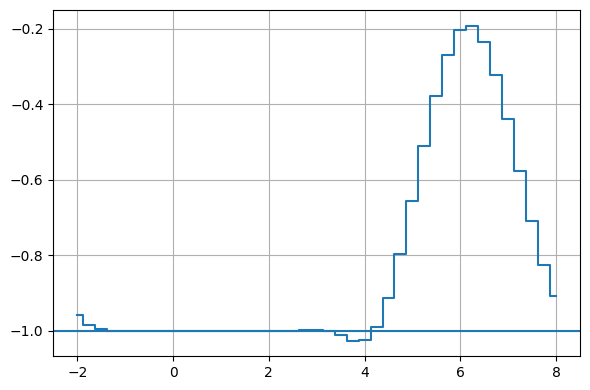

In [33]:
plt.figure(figsize=(6,4))
plt.step(x, solver.advectee.get(), where='mid')
plt.axhline(-1)
plt.grid(True)
plt.tight_layout()
plt.show()